### Sesi 2 MLP
By: Tegar Arifin Prasetyo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install tensorflow

In [ ]:
!pip install pandas matplotlib scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Load dataset
dataset = pd.read_csv('/content/advertising.csv')

# Lihat beberapa baris dataset
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [ ]:
dataset.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
# Cek nilai null
dataset.isnull().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [2]:
# Split data menjadi training dan testing set
from sklearn.model_selection import train_test_split

X = dataset.drop(['Sales'], axis=1)
y = dataset['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

NameError: name 'dataset' is not defined

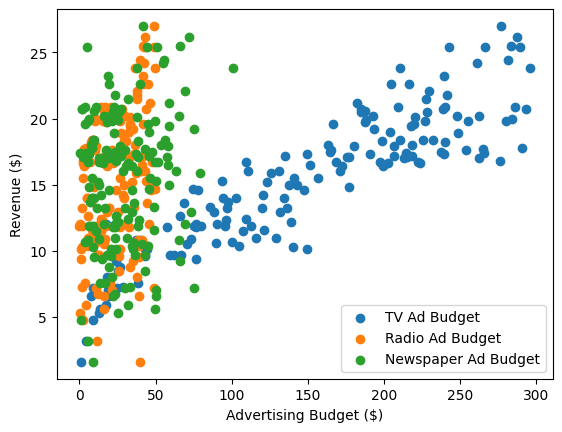

In [ ]:
# Membuat plot dari dataset
plt.scatter(X_train['TV'], y_train, label='TV Ad Budget') # Changed column name to 'TV'
plt.scatter(X_train['Radio'], y_train, label='Radio Ad Budget') # Changed column name to 'Radio'
plt.scatter(X_train['Newspaper'], y_train, label='Newspaper Ad Budget') # Changed column name to 'Newspaper'
plt.xlabel('Advertising Budget ($)')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Membangun model MLP
model = Sequential([
    Dense(512, input_shape=(3,), activation='relu'),  # Input layer
    Dense(512, activation='relu'),  # Hidden layer 1
    Dense(256, activation='relu'),  # Hidden layer 2
    Dense(1)  # Output layer (tidak perlu fungsi aktivasi karena ini masalah regresi)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │           2,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 396,289 (1.51 MB)

 Trainable params: 396,289 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, epochs=1400, validation_data=(X_test, y_test))

Epoch 1/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 130ms/step - loss: 325.3224 - mae: 14.8156 - val_loss: 102.2232 - val_mae: 9.2886
Epoch 2/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 63.7042 - mae: 7.0649 - val_loss: 60.0365 - val_mae: 6.0091
Epoch 3/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 36.5241 - mae: 4.6001 - val_loss: 22.0233 - val_mae: 4.1636
Epoch 4/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 21.2573 - mae: 4.0588 - val_loss: 17.9773 - val_mae: 3.2237
Epoch 5/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 12.7922 - mae: 2.7263 - val_loss: 8.4713 - val_mae: 2.5044
Epoch 6/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 7.9181 - mae: 2.3785 - val_loss: 8.3219 - val_mae: 2.2531
Epoch 7/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 5.4569 - mae: 1.8744 - val_loss: 8.0233 - val_mae: 2.2148
Epoch 8/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 5.4941 - mae: 1.9323 - val_loss: 6.7662 - val_mae: 2.0895
Epoch 9/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step 

In [ ]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"Mean Absolute Error pada data pengujian: {test_mae}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.5486 - mae: 1.2492 
Mean Absolute Error pada data pengujian: 1.2907737493515015


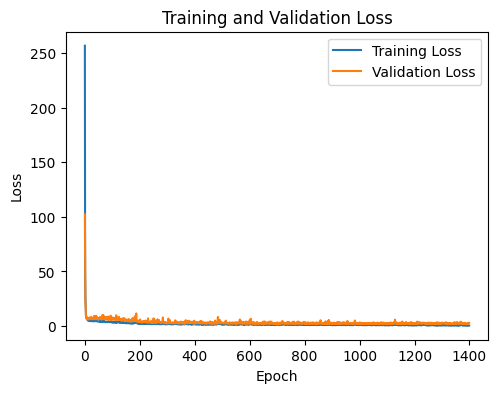

In [ ]:
# Plot Loss dan MAE selama pelatihan
plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


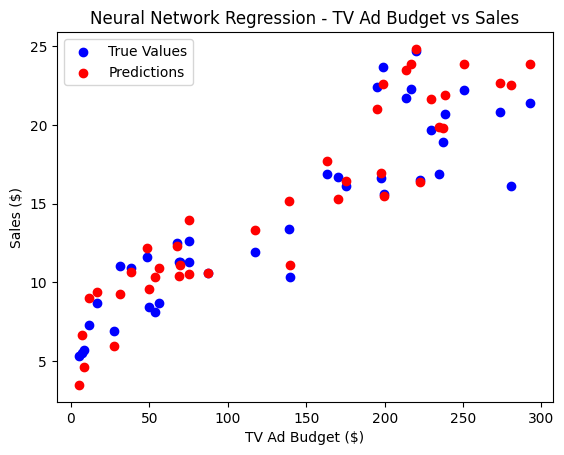

In [ ]:
y_pred_test = model.predict(X_test)

plt.scatter(X_test['TV'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['TV'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - TV Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

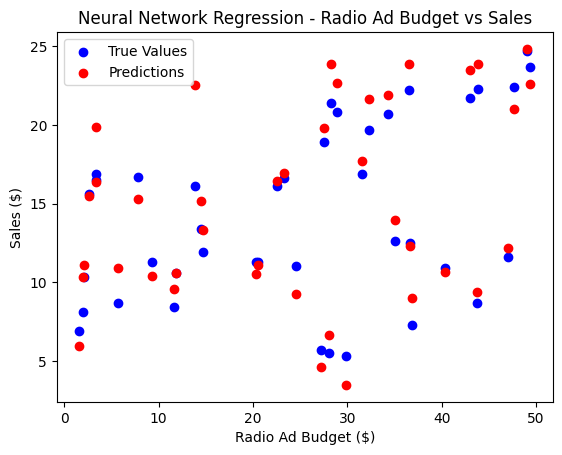

In [ ]:
plt.scatter(X_test['Radio'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Radio'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Radio Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Radio Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

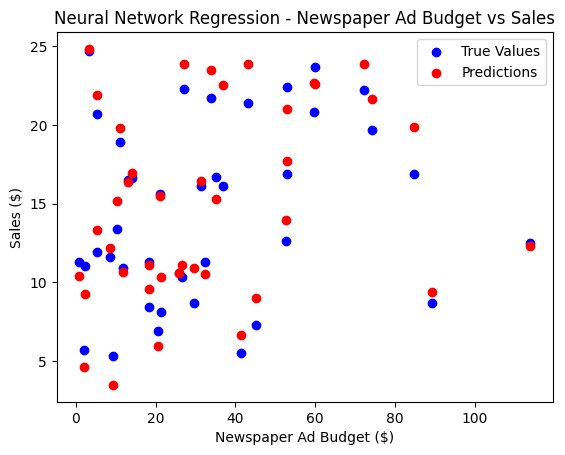

In [ ]:
plt.scatter(X_test['Newspaper'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Newspaper'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Newspaper Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Newspaper Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()


**Tugas** <br>

Silahkan jelaskan secara rinci kode program dan hasilnya (hint: lihat slide sesi teori ada gambaran secara umum, di tugas ini kalian detailkan maksud dan tujuannya), dikumpulkan paling lambat Rabu, 11 November 2026 jam 23.59 di ecourse